# PART 2 — 数値はどうやって予測する？
## 課題：コンクリートの圧縮強度を予測しよう

**Features → Regression → Numerical Prediction**

この課題では、UCI Machine Learning Repository の  
**Concrete Compressive Strength Dataset** を使います。

コンクリートの材料の量と材齢（Age）から、  
**コンクリートの圧縮強度（MPa）** を予測します。

今回は、これまでの実習で学んだ流れを使います。

### 課題で行うこと
1. データを読み込む
2. 8個の特徴量と正解 y を確認する
3. 学習用データとテスト用データに分ける
4. 線形回帰モデルを学習する
5. MAE / MSE / RMSE / R² で評価する
6. 実際の値と予測値をグラフで確認する
7. 決定木回帰とも比較する
8. 結果を自分の言葉で説明する

> このデータは機械学習の学習用データです。  
> 材料設計や建築・土木の安全性を判断するための実用モデルではありません。


## 1. 必要なライブラリを用意する

UCI Machine Learning Repository のデータを直接読み込むために  
`ucimlrepo` を使います。

最初のセルでは、Colab に `ucimlrepo` をインストールします。


In [2]:
!pip -q install ucimlrepo


## 2. ライブラリを読み込む

- `pandas`：表形式のデータを扱う
- `numpy`：数値計算
- `matplotlib`：グラフを描く
- `ucimlrepo`：UCI のデータセットを読み込む
- `scikit-learn`：回帰モデルと評価指標を使う


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 3. Concrete Compressive Strength Dataset を読み込む

UCI Machine Learning Repository では、このデータセットの ID は **165** です。

`fetch_ucirepo(id=165)` を使うと、  
特徴量と正解を pandas の表として読み込むことができます。


In [4]:
# UCI Machine Learning Repository からデータを読み込む
concrete = fetch_ucirepo(id=165)

# 8個の特徴量
X = concrete.data.features.copy()

# 正解：コンクリートの圧縮強度
y = concrete.data.targets.copy()

# 特徴量と正解を1つの表にまとめる
df = pd.concat([X, y], axis=1)

print("行数と列数:", df.shape)
display(df.head())


行数と列数: (1030, 9)


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 4. データの内容を確認する

このデータには **1,030個のコンクリート試料** があり、  
入力には **8個の特徴量** を使います。

| 特徴量 | 意味 | 単位 |
|---|---|---|
| Cement | セメントの量 | kg/m³ |
| Blast Furnace Slag | 高炉スラグの量 | kg/m³ |
| Fly Ash | フライアッシュの量 | kg/m³ |
| Water | 水の量 | kg/m³ |
| Superplasticizer | 高性能減水剤の量 | kg/m³ |
| Coarse Aggregate | 粗骨材の量 | kg/m³ |
| Fine Aggregate | 細骨材の量 | kg/m³ |
| Age | 材齢 | 日 |

### 正解 y

**Concrete compressive strength**

コンクリートの **圧縮強度** を表します。

単位は **MPa（メガパスカル）** です。

### 今回のポイント

このデータは標準化された値ではなく、  
材料の量や日数など、**元の単位を持つ数値**です。


In [5]:
print("列名:")
print(df.columns.tolist())

print("\nデータ数:", len(df))
print("欠損値の数:", df.isnull().sum().sum())


列名:
['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age', 'Concrete compressive strength']

データ数: 1030
欠損値の数: 0


## 5. データの範囲を確認する

各特徴量がどのくらいの値を取るのかを確認してみましょう。

`describe()` を使うと、平均値・最小値・最大値などを確認できます。


In [6]:
display(df.describe().round(2))


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
count,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00
mean,281.17,73.90,54.19,181.57,6.20,972.92,773.58,45.66,35.82
std,104.51,86.28,64.00,21.35,5.97,77.75,80.18,63.17,16.71
min,102.00,0.00,0.00,121.80,0.00,801.00,594.00,1.00,2.33
25%,192.38,0.00,0.00,164.90,0.00,932.00,730.95,7.00,23.71
50%,272.90,22.00,0.00,185.00,6.40,968.00,779.50,28.00,34.44
75%,350.00,142.95,118.30,192.00,10.20,1029.40,824.00,56.00,46.14
max,540.00,359.40,200.10,247.00,32.20,1145.00,992.60,365.00,82.60


## 6. Age と圧縮強度の関係を図で見る

コンクリートは時間が経つと強度が変化します。

横軸に **Age（材齢）**、  
縦軸に **圧縮強度** を取って、関係を見てみましょう。

このグラフでは1つの特徴量だけを見ていますが、  
実際のモデルでは **8個すべての特徴量** を使います。


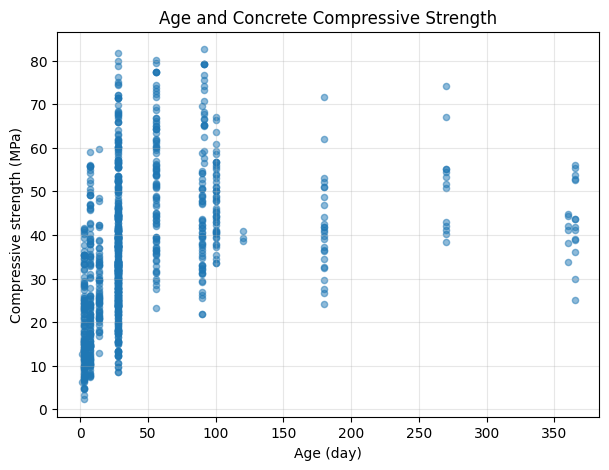

In [8]:
target_name = y.columns[0]

plt.figure(figsize=(7, 5))
plt.scatter(df["Age"], df[target_name], alpha=0.5, s=20)

plt.xlabel("Age (day)")
plt.ylabel("Compressive strength (MPa)")
plt.title("Age and Concrete Compressive Strength")
plt.grid(alpha=0.3)
plt.show()


## 7. Cement と圧縮強度の関係も見てみる

今度は、セメントの量と圧縮強度の関係を見てみましょう。

一つの特徴量だけで圧縮強度が完全に決まるわけではありません。  
水、骨材、混和材、材齢など、複数の特徴量が関係しています。


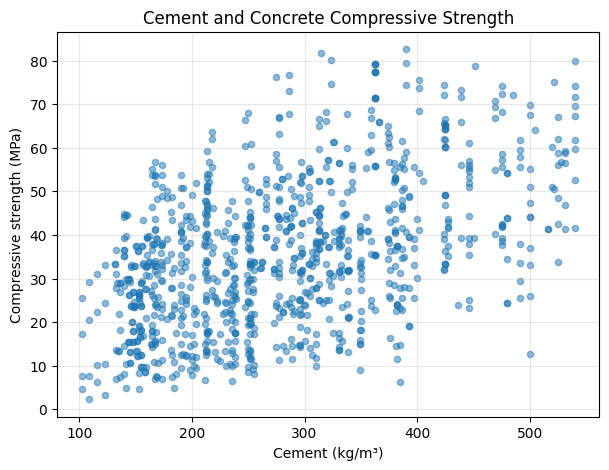

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(df["Cement"], df[target_name], alpha=0.5, s=20)

plt.xlabel("Cement (kg/m³)")
plt.ylabel("Compressive strength (MPa)")
plt.title("Cement and Concrete Compressive Strength")
plt.grid(alpha=0.3)
plt.show()


## 8. 入力 X と正解 y を確認する

すでにデータを読み込むときに、

- `X`：8個の特徴量
- `y`：圧縮強度

に分けてあります。

形を確認してみましょう。


In [10]:
print("X の形:", X.shape)
print("y の形:", y.shape)

display(X.head())
display(y.head())


X の形: (1030, 8)
y の形: (1030, 1)


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360


,Concrete compressive strength
0,79.99
1,61.89
2,40.27
3,41.05
4,44.30


## 9. y を1次元にする

今回の `y` は1列だけの DataFrame です。

scikit-learn で扱いやすいように、  
1次元の Series にしておきます。

`iloc[:, 0]` は、最初の列を取り出すという意味です。


In [11]:
y = y.iloc[:, 0]

print(type(y))
print("y の形:", y.shape)
display(y.head())


<class 'pandas.core.series.Series'>
y の形: (1030,)


,Concrete compressive strength
0,79.99
1,61.89
2,40.27
3,41.05
4,44.30


## 10. 学習用データとテスト用データに分ける

データの **80%を学習用（Train）**、  
**20%をテスト用（Test）** にします。

- Train：モデルを学習する
- Test：学習には使わず、最後に性能を確認する


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("学習用データ:", len(X_train))
print("テスト用データ:", len(X_test))


学習用データ: 824
テスト用データ: 206


# PART A — 線形回帰

まず、これまでの実習でも使った  
**Linear Regression（線形回帰）** で予測します。


## 11. 線形回帰モデルを学習する

`LinearRegression()` でモデルを作り、  
`fit()` で学習します。


In [13]:
# 線形回帰モデルを作る
linear_model = LinearRegression()

# 学習
linear_model.fit(X_train, y_train)

print("線形回帰の学習が完了しました。")


線形回帰の学習が完了しました。


## 12. テストデータを予測する

学習に使っていない `X_test` をモデルに入力します。

`predict()` の出力が、圧縮強度の予測値です。


In [14]:
linear_pred = linear_model.predict(X_test)

print("予測したデータ数:", len(linear_pred))
print("最初の5個の予測値:")
print(np.round(linear_pred[:5], 2))


予測したデータ数: 206
最初の5個の予測値:
[59.66 52.04 63.54 51.58 17.22]


## 13. 実際の値と予測値を並べる

予測値の単位も、正解と同じ **MPa** です。

実際の値と予測値の差も確認します。


In [15]:
linear_result = pd.DataFrame({
    "実際の強度（MPa）": y_test.values,
    "予測した強度（MPa）": linear_pred
})

linear_result["誤差（実際 - 予測）"] = (
    linear_result["実際の強度（MPa）"]
    - linear_result["予測した強度（MPa）"]
)

display(linear_result.head(10).round(2))


,実際の強度（MPa）,予測した強度（MPa）,誤差（実際 - 予測）
0,52.91,59.66,-6.75
1,55.90,52.04,3.86
2,74.50,63.54,10.96
3,35.30,51.58,-16.28
4,10.54,17.22,-6.68
5,44.28,39.87,4.41
6,23.69,26.70,-3.01
7,45.37,44.74,0.63
8,37.40,29.37,8.03
9,48.85,38.19,10.66


## 14. 線形回帰モデルを評価する

今回も4つの指標を使います。

- **MAE（Mean Absolute Error）**
- **MSE（Mean Squared Error）**
- **RMSE（Root Mean Squared Error）**
- **R²（Coefficient of Determination）**

### 見方

- MAE：小さいほどよい
- MSE：小さいほどよい
- RMSE：小さいほどよい
- R²：一般的には 1 に近いほどよい

MAE と RMSE は、圧縮強度と同じ **MPa** で考えることができます。


In [16]:
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_mse = mean_squared_error(y_test, linear_pred)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression")
print("MAE :", round(linear_mae, 2), "MPa")
print("MSE :", round(linear_mse, 2))
print("RMSE:", round(linear_rmse, 2), "MPa")
print("R²  :", round(linear_r2, 3))


Linear Regression
MAE : 7.75 MPa
MSE : 95.97
RMSE: 9.8 MPa
R²  : 0.628


## 15. 実際の値と予測値をグラフで確認する

横軸：実際の圧縮強度  
縦軸：予測した圧縮強度

点が赤い対角線に近いほど、  
実際の値に近い予測ができています。


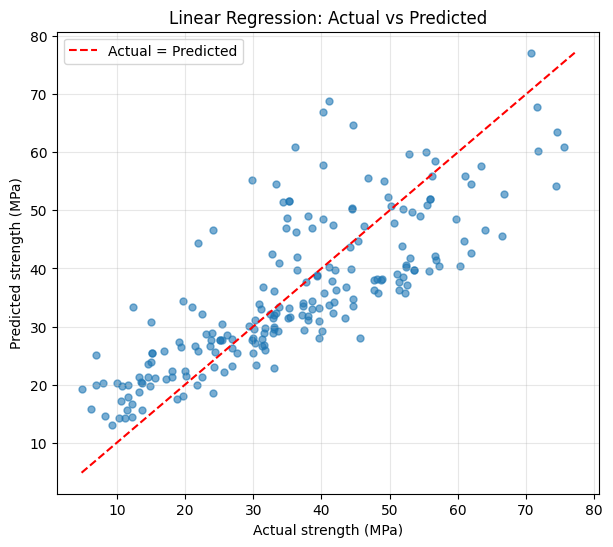

In [17]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, linear_pred, alpha=0.6, s=25)

min_value = min(y_test.min(), linear_pred.min())
max_value = max(y_test.max(), linear_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Actual = Predicted"
)

plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# PART B — 決定木回帰

次に、**Decision Tree Regressor（決定木回帰）** を使います。

分類で使った決定木は、  
数値を予測する回帰にも利用できます。

今回は、木が複雑になりすぎないように  
`max_depth=5` にします。


In [18]:
tree_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

print("決定木回帰の学習と予測が完了しました。")


決定木回帰の学習と予測が完了しました。


## 16. 決定木回帰を評価する

線形回帰と同じ評価指標を使います。


In [19]:
tree_mae = mean_absolute_error(y_test, tree_pred)
tree_mse = mean_squared_error(y_test, tree_pred)
tree_rmse = np.sqrt(tree_mse)
tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree Regressor")
print("MAE :", round(tree_mae, 2), "MPa")
print("MSE :", round(tree_mse, 2))
print("RMSE:", round(tree_rmse, 2), "MPa")
print("R²  :", round(tree_r2, 3))


Decision Tree Regressor
MAE : 7.46 MPa
MSE : 93.08
RMSE: 9.65 MPa
R²  : 0.639


## 17. 2つのモデルを比較する

同じテストデータを使って、  
線形回帰と決定木回帰の結果を比較します。

- MAE / RMSE：小さいほどよい
- R²：1に近いほどよい


In [20]:
comparison = pd.DataFrame({
    "モデル": ["Linear Regression", "Decision Tree"],
    "MAE (MPa)": [linear_mae, tree_mae],
    "RMSE (MPa)": [linear_rmse, tree_rmse],
    "R²": [linear_r2, tree_r2]
})

display(comparison.round(3))


,モデル,MAE (MPa),RMSE (MPa),R²
0,Linear Regression,7.746,9.796,0.628
1,Decision Tree,7.462,9.648,0.639


## 18. どの特徴量が重要だったかを見る

決定木では、どの特徴量を多く使って予測したかを  
`feature_importances_` で確認できます。

値が大きいほど、今回の決定木モデルで  
重要だった特徴量です。

> **注意：**  
> これは「原因」を証明する値ではありません。  
> このモデルが予測するときに、どの特徴量を多く利用したかを表します。


In [21]:
importance = pd.DataFrame({
    "特徴量": X.columns,
    "重要度": tree_model.feature_importances_
})

importance = importance.sort_values(
    "重要度",
    ascending=False
)

display(importance.round(3))


,特徴量,重要度
0,Cement,0.410
7,Age,0.340
3,Water,0.134
1,Blast Furnace Slag,0.078
2,Fly Ash,0.018
6,Fine Aggregate,0.010
4,Superplasticizer,0.010
5,Coarse Aggregate,0.000


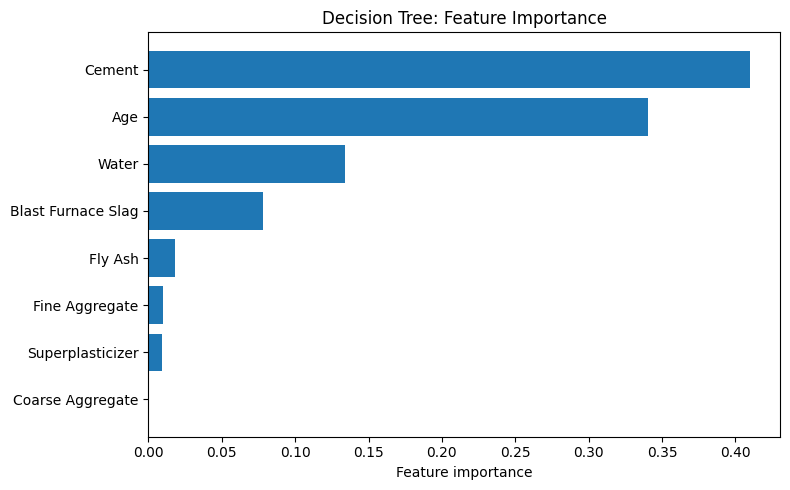

In [22]:
plt.figure(figsize=(8, 5))

plt.barh(
    importance["特徴量"][::-1],
    importance["重要度"][::-1]
)

plt.xlabel("Feature importance")
plt.title("Decision Tree: Feature Importance")
plt.tight_layout()
plt.show()


## 19. 深すぎる決定木で過学習を確認する

`max_depth` を指定しない決定木は、  
学習データに非常によく合わせることができます。

しかし、学習データに合わせすぎると、  
テストデータでの性能が下がることがあります。

これが **過学習（Overfitting）** です。


In [23]:
deep_tree = DecisionTreeRegressor(
    random_state=42
)

deep_tree.fit(X_train, y_train)

train_r2 = deep_tree.score(X_train, y_train)
test_r2 = deep_tree.score(X_test, y_test)

print("深さを制限しない決定木")
print("Train R²:", round(train_r2, 3))
print("Test  R²:", round(test_r2, 3))


深さを制限しない決定木
Train R²: 0.997
Test  R²: 0.835


In [25]:
deep_tree_pred = deep_tree.predict(X_test)
deep_tree_mae = mean_absolute_error(y_test, deep_tree_pred)
deep_tree_mse = mean_squared_error(y_test, deep_tree_pred)
deep_tree_rmse = np.sqrt(deep_tree_mse)
deep_tree_r2 = r2_score(y_test, deep_tree_pred)

print("deep_tree Regression")
print("MAE :", round(deep_tree_mae, 2), "MPa")
print("MSE :", round(deep_tree_mse, 2))
print("RMSE:", round(deep_tree_rmse, 2), "MPa")
print("R²  :", round(deep_tree_r2, 3))

deep_tree Regression
MAE : 4.29 MPa
MSE : 42.58
RMSE: 6.53 MPa
R²  : 0.835


In [26]:
print("실제 트리의 깊이:", deep_tree.get_depth())

실제 트리의 깊이: 18


In [28]:
from sklearn.model_selection import GridSearchCV

# 1. 試行する max_depth の範囲を設定（例: 1から15まで）
param_grid = {'max_depth': range(1, 20)}

# 2. 交差検証（Cross-Validation, cv=5）を含む GridSearchCV オブジェクトの作成
grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,                # データを5つの分割に分けて汎用性を検証
    scoring='r2',        # 評価指標（R² スコア）
    n_jobs=-1
)

# 3. 学習の実行
grid_search.fit(X_train, y_train)

# 4. 結果の確認
print("汎用性と精度を両立した最適な max_depth:", grid_search.best_params_['max_depth'])
print("最適な検証 R² スコア:", round(grid_search.best_score_, 3))

汎用性と精度を両立した最適な max_depth: 16
最適な検証 R² スコア: 0.819


# まとめ

今回の課題では、コンクリートの材料と材齢から  
**圧縮強度という連続した数値**を予測しました。

### 回帰の基本的な流れ

**1. データを確認する**

入力 X と正解 y は何か？

↓

**2. Train / Test に分ける**

↓

**3. モデルを学習する**

`fit()`

↓

**4. テストデータを予測する**

`predict()`

↓

**5. 評価する**

MAE / MSE / RMSE / R²

↓

**6. 異なるモデルを比較する**

Linear Regression / Decision Tree Regressor

### 今回の X と y

- **X**：8個の材料・材齢の特徴量
- **y**：コンクリートの圧縮強度（MPa）


# 提出課題

Colab を上から順番に実行し、次の問いに答えてください。

### 問1
入力 **X** の8個の特徴量を書いてください。

### 問2
正解 **y** は何を表していますか。  
また、その単位は何ですか。

### 問3
データはいくつあり、学習用とテスト用はそれぞれ何件になりましたか。

### 問4
線形回帰の次の値を書いてください。

- MAE
- MSE
- RMSE
- R²

### 問5
決定木回帰の次の値を書いてください。

- MAE
- RMSE
- R²

### 問6
今回の結果では、線形回帰と決定木回帰のどちらがよい結果でしたか。  
評価指標を使って理由を説明してください。

### 問7
決定木の Feature Importance で、最も重要度が高かった特徴量は何でしたか。

### 問8
`max_depth` を指定しない決定木の

- Train R²
- Test R²

を比較し、**過学習**について説明してください。

### 問9
Age と圧縮強度の散布図、または Cement と圧縮強度の散布図を見て、  
気づいたことを1つ自分の言葉で書いてください。

---

## 提出するもの

- MAE / MSE / RMSE / R² の結果
- Actual vs Predicted のグラフ
- Feature Importance の結果
- 問1〜問9への回答

**AI を利用しても構いませんが、結果の意味は自分の言葉で説明してください。**


## 参考

データセット：

**UCI Machine Learning Repository  
Concrete Compressive Strength Dataset（ID: 165）**

- データ数：1,030
- 入力特徴量：8
- 正解：Concrete compressive strength
- 単位：MPa
- 欠損値：なし

この実習では、回帰の基本的な流れを理解することを目的として、  
複雑な前処理やハイパーパラメータ探索は行っていません。
